In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Configuração visual dos gráficos
plt.rcParams['figure.figsize'] = (12, 6)

# População aproximada da França
N = 67_500_000

In [14]:
# Fonte de dados (Johns Hopkins University)
URL = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"

# Ler o CSV
df = pd.read_csv(URL)

# Filtrar França e somar províncias (para pegar o país todo)
france_data = df[df['Country/Region'] == 'France'].iloc[:, 4:].sum(axis=0)

# Converter índice para data
france_data.index = pd.to_datetime(france_data.index, errors='coerce')

# --- Dados Acumulados (y_real) ---
y_real = france_data.values.astype(float)
x_days = np.arange(len(y_real))

# --- Dados Diários (Cálculo da diferença dia a dia) ---
# O prepend mantém o tamanho do array igual ao original
y_daily_real = np.diff(y_real, prepend=0)
# Suavização rápida (Média móvel de 7 dias) para facilitar a visualização
y_daily_smooth = pd.Series(y_daily_real).rolling(window=7).mean().fillna(0).values

print(f"Dados carregados: {len(x_days)} dias.")
print(f"Total acumulado: {y_real[-1]:,.0f} casos.")

Dados carregados: 1143 dias.
Total acumulado: 39,866,718 casos.


C:\Users\pedro\AppData\Local\Temp\ipykernel_15592\1476120899.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  france_data.index = pd.to_datetime(france_data.index, errors='coerce')


In [15]:
# --- 1. MODELO SIR (Core) ---
def run_sir(t, beta, gamma):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t))
    Daily = np.zeros(len(t)) # Para guardar casos diários
    
    I[0] = y_real[0] if y_real[0] > 0 else 1.0
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        
        S[i+1] = max(0, S[i] - new_inf)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = R[i] + new_rec
        Daily[i+1] = new_inf
        
    return S, I, R, Daily, (I + R)

# Wrapper para o curve_fit
def fit_sir(t, beta, gamma):
    _, _, _, _, accumulated = run_sir(t, beta, gamma)
    return accumulated


# --- 2. MODELO SIRS (Core) ---
def run_sirs(t, beta, gamma, xi):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t))
    C = np.zeros(len(t)); Daily = np.zeros(len(t))
    
    I[0] = y_real[0] if y_real[0] > 0 else 1.0
    C[0] = I[0]
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i] # Perda de imunidade
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        Daily[i+1] = new_inf
        C[i+1] = C[i] + new_inf
        
    return S, I, R, Daily, C

def fit_sirs(t, beta, gamma, xi):
    _, _, _, _, accumulated = run_sirs(t, beta, gamma, xi)
    return accumulated


# --- 3. MODELO SIRS DINÂMICO (Core) ---
num_nodes = 15 # Aumentei os nós para capturar mais ondas
x_nodes = np.linspace(0, len(x_days), num_nodes)

def run_dynamic(t, gamma, xi, betas_array):
    S = np.zeros(len(t)); I = np.zeros(len(t)); R = np.zeros(len(t))
    C = np.zeros(len(t)); Daily = np.zeros(len(t))
    
    I[0] = y_real[0] if y_real[0] > 0 else 1.0
    C[0] = I[0]
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        # Interpola o Beta do dia
        beta_t = np.interp(i, x_nodes, betas_array)
        
        new_inf = (beta_t * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        Daily[i+1] = new_inf
        C[i+1] = C[i] + new_inf
        
    return S, I, R, Daily, C

def fit_dynamic(t, gamma, xi, *betas):
    _, _, _, _, accumulated = run_dynamic(t, gamma, xi, betas)
    return accumulated

In [16]:
print("Otimizando modelos... (Isso pode levar alguns instantes)")

# 1. Ajuste SIR
popt_sir, _ = curve_fit(fit_sir, x_days, y_real, p0=[0.1, 0.05], bounds=(0, [5.0, 1.0]))

# 2. Ajuste SIRS
popt_sirs, _ = curve_fit(fit_sirs, x_days, y_real, p0=[0.1, 0.05, 0.001], bounds=(0, [5.0, 1.0, 1.0]))

# 3. Ajuste Dinâmico
# Chutes iniciais: Gamma, Xi, e depois vários Betas iguais
initial_guess = [0.05, 0.005] + [0.15] * num_nodes
lower_bounds = [0.0, 0.0] + [0.0] * num_nodes
upper_bounds = [1.0, 1.0] + [5.0] * num_nodes

popt_dyn, _ = curve_fit(fit_dynamic, x_days, y_real, 
                        p0=initial_guess, 
                        bounds=(lower_bounds, upper_bounds),
                        maxfev=15000)

print("Otimização concluída!")

Otimizando modelos... (Isso pode levar alguns instantes)
Otimização concluída!


In [17]:
# Agora rodamos os modelos com os parâmetros ótimos para obter S, I, R e Diários

# SIR
S_sir, I_sir, R_sir, Daily_sir, Acc_sir = run_sir(x_days, *popt_sir)

# SIRS
S_sirs, I_sirs, R_sirs, Daily_sirs, Acc_sirs = run_sirs(x_days, *popt_sirs)

# Dinâmico
gamma_dyn = popt_dyn[0]
xi_dyn = popt_dyn[1]
betas_dyn = popt_dyn[2:]
S_dyn, I_dyn, R_dyn, Daily_dyn, Acc_dyn = run_dynamic(x_days, gamma_dyn, xi_dyn, betas_dyn)

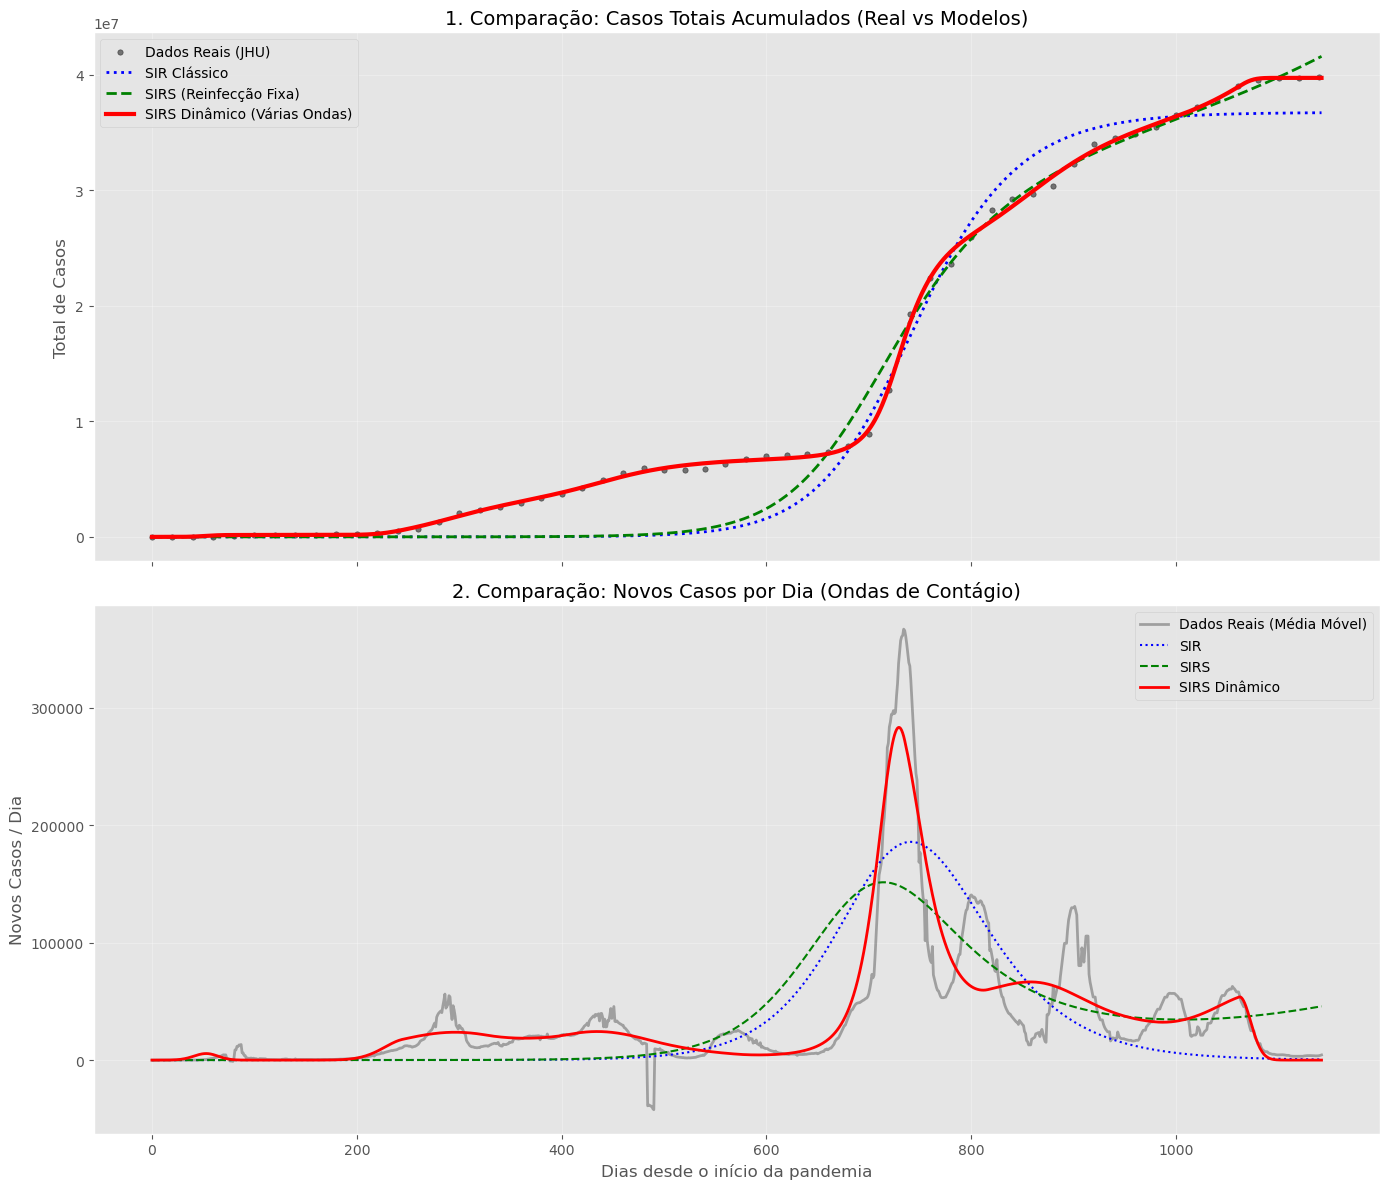

In [18]:
# Criar uma figura com 2 subplots principais para comparação Geral
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), sharex=True)

# --- GRÁFICO 1: Casos Acumulados ---
ax1.set_title("1. Comparação: Casos Totais Acumulados (Real vs Modelos)", fontsize=14)
ax1.scatter(x_days[::20], y_real[::20], color='black', s=15, label='Dados Reais (JHU)', alpha=0.5)
ax1.plot(x_days, Acc_sir, label='SIR Clássico', linestyle=':', color='blue', linewidth=2)
ax1.plot(x_days, Acc_sirs, label='SIRS (Reinfecção Fixa)', linestyle='--', color='green', linewidth=2)
ax1.plot(x_days, Acc_dyn, label='SIRS Dinâmico (Várias Ondas)', color='red', linewidth=3)
ax1.set_ylabel("Total de Casos")
ax1.legend()
ax1.grid(True, alpha=0.3)

# --- GRÁFICO 2: Casos Diários (Novos por dia) ---
ax2.set_title("2. Comparação: Novos Casos por Dia (Ondas de Contágio)", fontsize=14)
# Plotamos a média móvel dos dados reais para limpar o ruído
ax2.plot(x_days, y_daily_smooth, color='black', alpha=0.3, label='Dados Reais (Média Móvel)', linewidth=2)
ax2.plot(x_days, Daily_sir, label='SIR', linestyle=':', color='blue')
ax2.plot(x_days, Daily_sirs, label='SIRS', linestyle='--', color='green')
ax2.plot(x_days, Daily_dyn, label='SIRS Dinâmico', color='red', linewidth=2)
ax2.set_ylabel("Novos Casos / Dia")
ax2.set_xlabel("Dias desde o início da pandemia")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

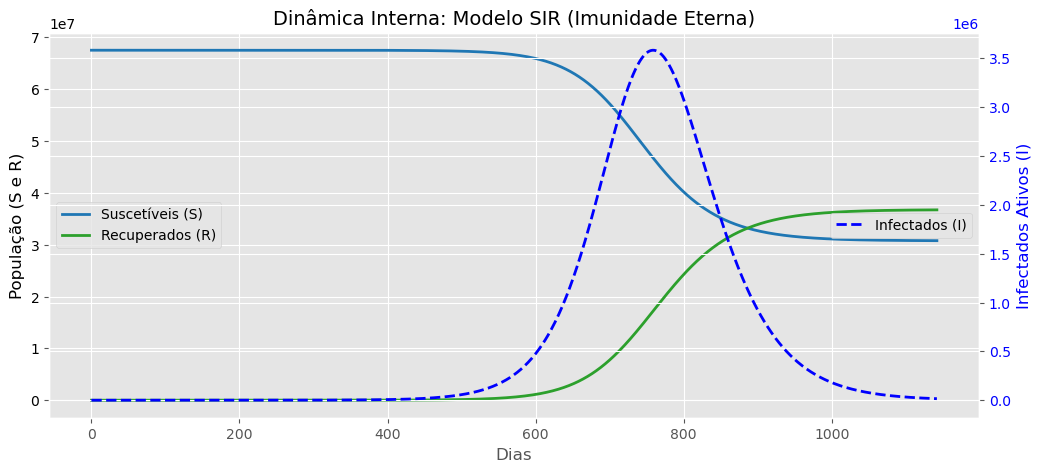

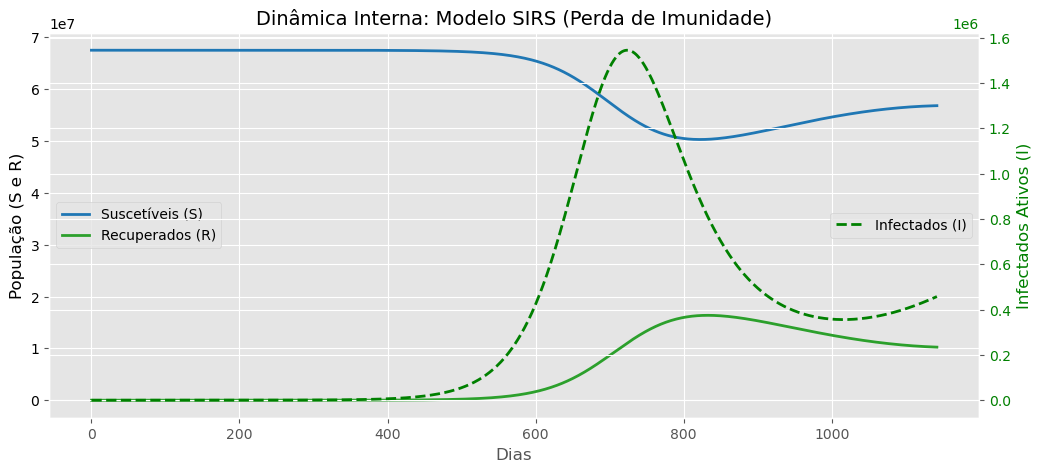

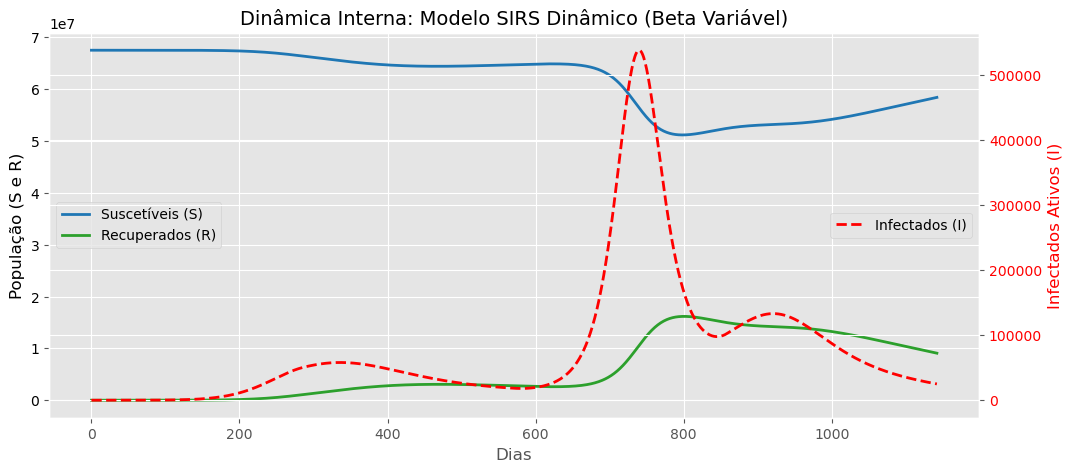

In [11]:
# Criar 3 figuras separadas para ver a dinâmica interna de cada um

def plot_dynamics(model_name, S, I, R, color_code):
    fig, ax1 = plt.subplots(figsize=(12, 5))
    
    ax1.set_title(f"Dinâmica Interna: Modelo {model_name}", fontsize=14)
    ax1.set_xlabel("Dias")
    ax1.set_ylabel("População (S e R)", color='black')
    
    # Plotar Suscetíveis e Recuperados no eixo da esquerda (Escala grande)
    ax1.plot(x_days, S, label='Suscetíveis (S)', color='tab:blue', linewidth=2)
    ax1.plot(x_days, R, label='Recuperados (R)', color='tab:green', linewidth=2)
    ax1.tick_params(axis='y', labelcolor='black')
    ax1.legend(loc='center left')
    
    # Plotar Infectados no eixo da direita (Escala menor)
    ax2 = ax1.twinx() 
    ax2.set_ylabel("Infectados Ativos (I)", color=color_code)
    ax2.plot(x_days, I, label='Infectados (I)', color=color_code, linewidth=2, linestyle='--')
    ax2.tick_params(axis='y', labelcolor=color_code)
    ax2.legend(loc='center right')
    
    plt.show()

# 1. Dinâmica do SIR
plot_dynamics("SIR (Imunidade Eterna)", S_sir, I_sir, R_sir, 'blue')

# 2. Dinâmica do SIRS
plot_dynamics("SIRS (Perda de Imunidade)", S_sirs, I_sirs, R_sirs, 'green')

# 3. Dinâmica do SIRS Dinâmico
plot_dynamics("SIRS Dinâmico (Beta Variável)", S_dyn, I_dyn, R_dyn, 'red')